# Sea level during a free wobble

No load. The rotation starts with a prescribed pole offset and then wobbles freely at the Chandler period. The sea-level change
is the ocean pole tide: the centrifugal potential of the wobble, $\psi_{21}=r\boldsymbol\omega$, and the solid-Earth and ocean response to it.
It is a degree-2, order-1 pattern that turns with the pole. Each frame is one sea-level solve with $\zeta=0$ and the current $\boldsymbol\omega(t)$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from matplotlib.animation import PillowWriter
from IPython.display import Image

import solver_dynamic as sd
import examples_dynamic_helper as eh

/space/dah94/rotation/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#=======================================================================
# Parameters
#=======================================================================

lmax = 32
rtol = 1e-10
year_days = 365.25

# Initial pole offset (mas)
wobble_mas = 100.0

# Time step (days), number of Chandler periods shown, and frames per second
dt_days = 7.0
n_periods = 1.0
frames_per_second = 12

gif_path = "animations/free_wobble_sea_level.gif"
gif_path_no_2 = "animations/free_wobble_sea_level_with_without_degree_2.gif"

In [3]:
#=======================================================================
# Earth model, and the free wobble with the ocean
#=======================================================================

state = sd.make_state(lmax)
model = state.model
constants = sd.rotation_constants(model)

day = float(sd.days_to_model_time(1.0, constants))
length_scale_mm = constants["length_scale"] * 1e3

no_load = sd.SeparableLoad([(model.zero_grid(), 0.0)])
omega_0 = np.array([wobble_mas / sd.omega_to_mas(1.0, constants), 0.0])

# A first run of 1.5 years fixes the Chandler period, then the shown run covers n_periods of it
rhs = sd.forward_rhs(state, constants, no_load, rtol=rtol)
t_probe = np.arange(0.0, 1.5 * year_days * day, dt_days * day)
t_cw_days = eh.wobble_period_days(
    sd.model_time_to_days(t_probe, constants),
    sd.integrate(rhs, omega_0, t_probe),
)
t = np.arange(0.0, n_periods * t_cw_days * day, dt_days * day)
omega = sd.integrate(rhs, omega_0, t)
t_days = sd.model_time_to_days(t, constants)
pole_mas = sd.omega_to_mas(omega, constants)
print(f"T_CW = {t_cw_days:.2f} d; {len(t)} frames")

T_CW = 476.66 d; 69 frames


In [4]:
#=======================================================================
# Sea level at every frame (mm)
#=======================================================================

# Keep the full fields (defined everywhere), and mask to the ocean for plotting
sea_level_fields = [sd.sea_level(state, constants, no_load, t[n], omega[n], rtol=rtol) for n in range(len(t))]
ocean_mask = np.where(state.ocean_function.data > 0, 1.0, np.nan)
sea_level_mm = np.array([field.data for field in sea_level_fields]) * length_scale_mm * ocean_mask
print(f"max |xi| over the ocean and the period: {np.nanmax(np.abs(sea_level_mm)):.2f} mm, for a {wobble_mas:.0f} mas wobble")

max |xi| over the ocean and the period: 4.76 mm, for a 100 mas wobble


saved animations/free_wobble_sea_level.gif


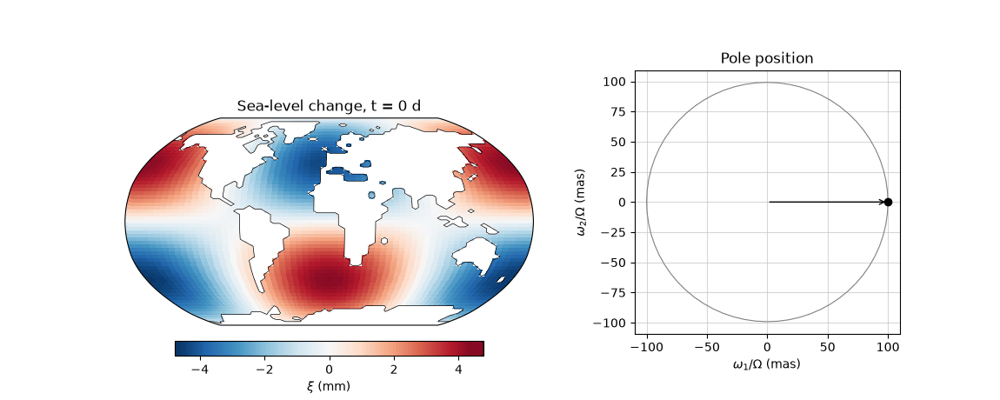

In [5]:
#=======================================================================
# Animation: sea level map and pole path
#=======================================================================

animation = eh.sea_level_animation(
    state,
    [sea_level_mm],
    ["Sea-level change"],
    pole_mas,
    t_days,
    frames_per_second=frames_per_second,
)

os.makedirs(os.path.dirname(gif_path), exist_ok=True)
animation.save(gif_path, writer=PillowWriter(fps=frames_per_second))
print(f"saved {gif_path}")
Image(filename=gif_path)

## Without degree 2

The same frames with degree 2 (all orders) removed from $\xi$, shown beside the full field. Each map has its own colour scale. Each field is expanded in spherical harmonics, its $l=2$ coefficients are set to
zero, and it is synthesised again, before the ocean mask is applied. The degree-2 part is the direct pole tide. What remains is the response
spread to other degrees by the ocean: the load $\rho_wC\xi$ on the irregular ocean, and the self-gravitation and deformation it causes.

In [6]:
#=======================================================================
# Remove degree 2 from the sea level at every frame (mm)
#=======================================================================

sea_level_no_2_mm = np.array([
    eh.remove_degrees(model, field, [2]).data for field in sea_level_fields
]) * length_scale_mm * ocean_mask
print(f"max |xi| without degree 2: {np.nanmax(np.abs(sea_level_no_2_mm)):.2f} mm "
      f"({np.nanmax(np.abs(sea_level_no_2_mm)) / np.nanmax(np.abs(sea_level_mm)):.1%} of the full field)")

max |xi| without degree 2: 0.58 mm (12.1% of the full field)


saved animations/free_wobble_sea_level_with_without_degree_2.gif


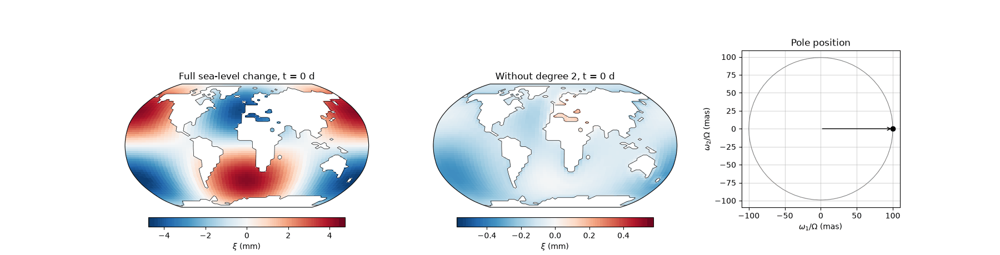

In [7]:
#=======================================================================
# Animation with and without degree 2, side by side (each map has its own colour scale)
#=======================================================================

animation_no_2 = eh.sea_level_animation(
    state,
    [sea_level_mm, sea_level_no_2_mm],
    ["Full sea-level change", "Without degree 2"],
    pole_mas,
    t_days,
    frames_per_second=frames_per_second,
)

animation_no_2.save(gif_path_no_2, writer=PillowWriter(fps=frames_per_second))
print(f"saved {gif_path_no_2}")
Image(filename=gif_path_no_2)